# Day 8: Feature Detection
Today we will cover:
- Harris Corners
- SIFT (Scale-Invariant Feature Transform)
- ORB (Oriented FAST and Rotated BRIEF)

## Why Feature Detection?
Feature detection identifies distinctive points in images (corners, blobs, edges) that can be matched across views. This is fundamental for tasks like object recognition, motion tracking, and panorama stitching.

## Harris Corner Detection
Harris detects corners by analyzing intensity changes in multiple directions.
- Pros: Simple, effective for corner detection.
- Cons: Not scale/rotation invariant.

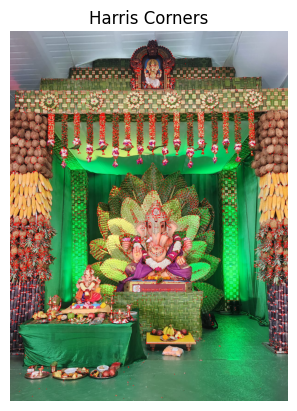

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('Ganesh3.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

gray = np.float32(gray)
dst = cv2.cornerHarris(gray, 2, 3, 0.04)
img_harris = img.copy()
img_harris[dst > 0.01 * dst.max()] = [0,0,255]

plt.imshow(cv2.cvtColor(img_harris, cv2.COLOR_BGR2RGB))
plt.title("Harris Corners")
plt.axis('off')
plt.show()

## SIFT (Scale-Invariant Feature Transform)
SIFT detects and describes keypoints robust to scale and rotation.
- Pros: Very robust, widely used.
- Cons: Computationally heavy, patented (but now free in OpenCV ≥ 4.4).

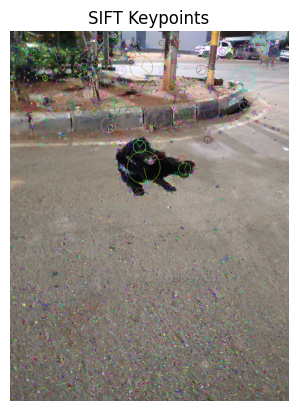

In [7]:
import cv2
import matplotlib.pyplot as plt

# Load the image
img = cv2.imread('blackdog.jpg')   # <-- make sure the path is correct
if img is None:
    raise ValueError("Image not found. Check the file path.")

# Convert to grayscale (uint8)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and descriptors
kp, des = sift.detectAndCompute(gray, None)

# Draw keypoints on the original image
img_sift = cv2.drawKeypoints(img, kp, None,
                             flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

# Display with matplotlib (convert BGR → RGB for correct colors)
plt.imshow(cv2.cvtColor(img_sift, cv2.COLOR_BGR2RGB))
plt.title("SIFT Keypoints")
plt.axis('off')
plt.show()

## ORB (Oriented FAST and Rotated BRIEF)
ORB is a fast, efficient alternative to SIFT.
- Pros: Free, fast, rotation invariant.
- Cons: Less robust than SIFT for scale changes.

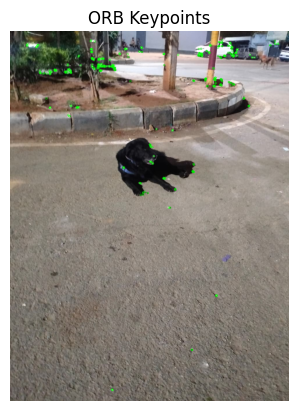

In [8]:
orb = cv2.ORB_create()
kp_orb, des_orb = orb.detectAndCompute(gray, None)
img_orb = cv2.drawKeypoints(img, kp_orb, None, color=(0,255,0), flags=0)

plt.imshow(cv2.cvtColor(img_orb, cv2.COLOR_BGR2RGB))
plt.title("ORB Keypoints")
plt.axis('off')
plt.show()

## Exercise: Detect Keypoints in Images
Try running Harris, SIFT, and ORB on different images (e.g., building facades, natural scenes). Compare the number and distribution of keypoints.

## Mini Project: Panorama Stitching
We will use feature detection + matching to stitch two overlapping images into a panorama.

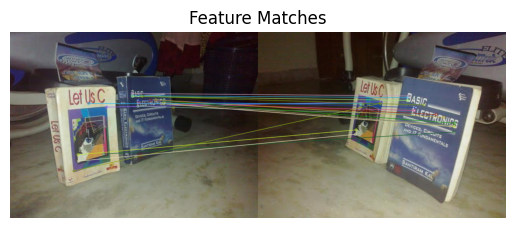

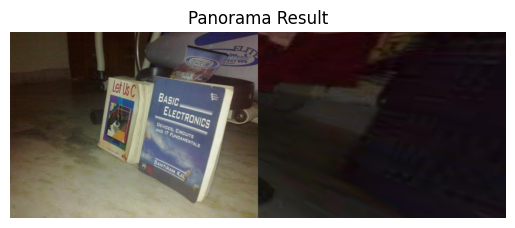

In [9]:
# Load two overlapping images
img1 = cv2.imread('left.jpg')
img2 = cv2.imread('right.jpg')

# Convert to grayscale
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# Detect ORB keypoints and descriptors
orb = cv2.ORB_create()
kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)

# Match features
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x:x.distance)

# Draw matches
img_matches = cv2.drawMatches(img1, kp1, img2, kp2, matches[:20], None, flags=2)
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
plt.title("Feature Matches")
plt.axis('off')
plt.show()

# Estimate homography
src_pts = np.float32([ kp1[m.queryIdx].pt for m in matches ]).reshape(-1,1,2)
dst_pts = np.float32([ kp2[m.trainIdx].pt for m in matches ]).reshape(-1,1,2)
M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,5.0)

# Warp and stitch
h,w = img1.shape[:2]
result = cv2.warpPerspective(img1, M, (w + img2.shape[1], h))
result[0:img2.shape[0], 0:img2.shape[1]] = img2

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Panorama Result")
plt.axis('off')
plt.show()